In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("loan_approval_data.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

Handling Missing Value

In [3]:
categorical_cols = df.select_dtypes(include = ["object"]).columns
numerical_cols = df.select_dtypes(include = ["number"]).columns

In [4]:
from sklearn.impute import SimpleImputer

num_imp = SimpleImputer(strategy = "mean")
df[numerical_cols]= num_imp.fit_transform(df[numerical_cols])

cat_imp = SimpleImputer(strategy = "most_frequent")
df[categorical_cols]= cat_imp.fit_transform(df[categorical_cols])

EDA - Exploratory data analysis

Text(0.5, 1.0, 'Is loan approved or not')

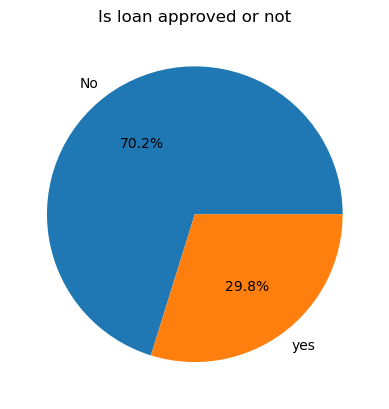

In [5]:
# how balanced our classes are ?
class_count = df["Loan_Approved"].value_counts()

plt.pie(class_count, labels = ["No","yes"], autopct="%1.1f%%")
plt.title("Is loan approved or not")

[Text(0, 0, '722'), Text(0, 0, '278')]

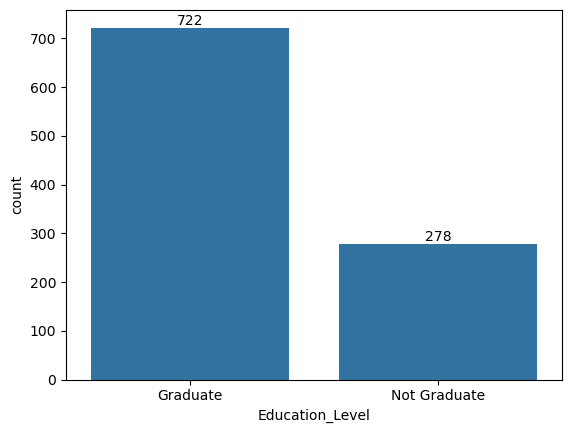

In [6]:
# analyze categories

gender_cnt = df["Education_Level"].value_counts()
ax = sns.barplot(gender_cnt)
ax.bar_label(ax.containers[0])

<Axes: xlabel='Applicant_Income', ylabel='Count'>

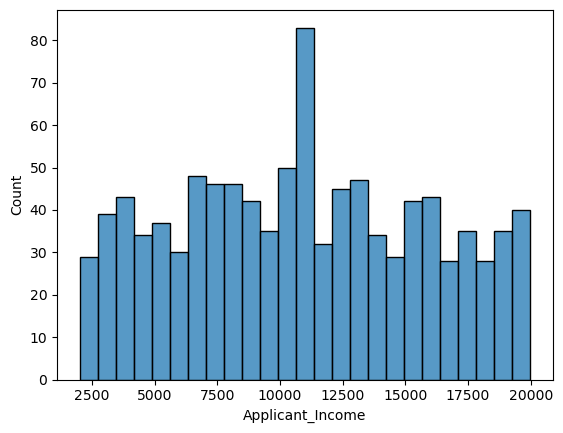

In [7]:
# analyze income
sns.histplot(
    data = df,
    x = "Applicant_Income",
    bins = 25
)

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

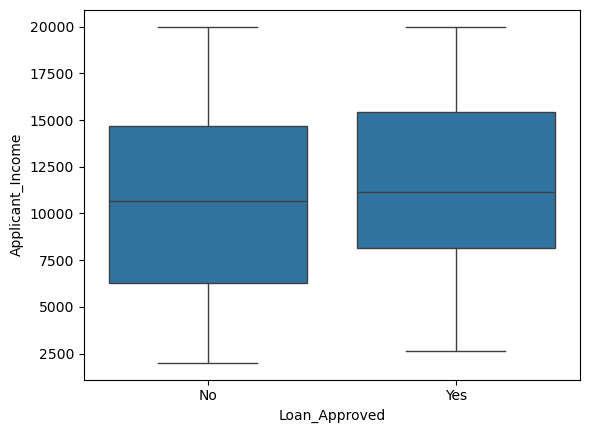

In [8]:
# outliers - box plots

sns.boxplot(
    data=df,
    x="Loan_Approved",
    y= "Applicant_Income"
)

<Axes: xlabel='Loan_Approved', ylabel='Savings'>

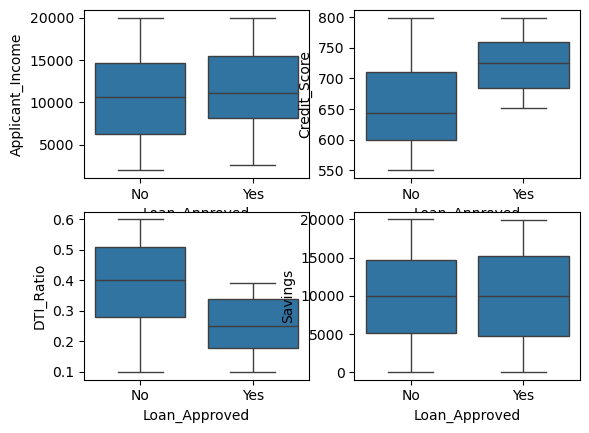

In [9]:
fig,axes = plt.subplots(2,2)

sns.boxplot(ax = axes[0,0], data=df,x="Loan_Approved",y= "Applicant_Income")
sns.boxplot(ax = axes[0,1], data=df,x="Loan_Approved",y= "Credit_Score")
sns.boxplot(ax = axes[1,0], data=df,x="Loan_Approved",y= "DTI_Ratio")
sns.boxplot(ax = axes[1,1], data=df,x="Loan_Approved",y= "Savings")

<Axes: xlabel='Credit_Score', ylabel='Count'>

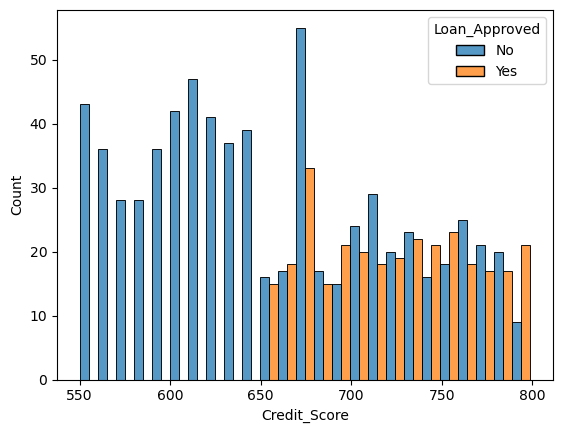

In [10]:
# analyze income
sns.histplot(
    data = df,
    x = "Credit_Score",
    hue = "Loan_Approved",
    multiple = "dodge",
    bins = 25
)

In [11]:
# Remove Application Id
df = df.drop("Applicant_ID",axis = 1)

In [12]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


In [14]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

le = LabelEncoder()
df["Education_Level"] = le.fit_transform(df["Education_Level"])
df["Loan_Approved"] = le.fit_transform(df["Loan_Approved"])


In [30]:
cols = ["Employment_Status", "Marital_Status", "Loan_Purpose", "Property_Area", "Gender","Employer_Category"]
ohe = OneHotEncoder(drop ="first", sparse_output= False, handle_unknown="ignore")
encoded = ohe.fit_transform(df[cols])

encoded_df = pd.DataFrame(encoded,columns = ohe.get_feature_names_out(cols), index =df.index)

df = pd.concat([df.drop(columns = cols), encoded_df], axis = 1)

In [31]:
df.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


Corelation Heatmap

In [39]:
num_cols = df.select_dtypes(include="number")
corr_matrix = num_cols.corr()

# sns.heatmap(
#     corr_matrix,
#     annot = True,
#     cmap = "coolwarm",
#     fmt = ".2f"
# )

In [40]:
num_cols.corr() ["Loan_Approved"].sort_values(ascending= False)


Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Property_Area_Urban                0.025963
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Property_Area_Semiurban           -0.012967
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed      -0.044464
Education_Level                 

Train_Test_Split + Feature Scaling

In [41]:
x = df.drop("Loan_Approved", axis = 1)
y = df["Loan_Approved"]


In [44]:
x_train,x_test,y_train,y_test = train_test_split(
    x,y, test_size = 0.2, random_state =42
)

In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.fit_transform(x_test)

Train_Evaluate

In [48]:
#logistic regression model

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

log_model =  LogisticRegression()
log_model.fit(x_train_scaled,y_train)

y_pred = log_model.predict(x_test_scaled)

print("Logistic Regression Model")
print("precision: ", precision_score(y_test,y_pred))
print("Recall", recall_score(y_test,y_pred))
print("Accuracy", f1_score(y_test,y_pred))
print("CM", confusion_matrix(y_test,y_pred))

Logistic Regression Model
precision:  0.8518518518518519
Recall 0.7540983606557377
Accuracy 0.8
CM [[131   8]
 [ 15  46]]


In [56]:
# for KNNN
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=7)
knn_model.fit(x_train_scaled,y_train)

yz_pred = knn_model.predict(x_test_scaled)

print("Logistic Regression Model")
print("precision: ", precision_score(y_test,yz_pred))
print("Recall", recall_score(y_test,yz_pred))
print("Accuracy", f1_score(y_test,yz_pred))
print("CM", confusion_matrix(y_test,yz_pred))

Logistic Regression Model
precision:  0.6585365853658537
Recall 0.4426229508196721
Accuracy 0.5294117647058824
CM [[125  14]
 [ 34  27]]


In [59]:
# for Naive Bayes
# Best model on the basis of precision => Naive Bayes

from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(x_train_scaled,y_train)

yz_pred = nb_model.predict(x_test_scaled)

print("Logistic Regression Model")
print("precision: ", precision_score(y_test,yz_pred))
print("Recall", recall_score(y_test,yz_pred))
print("Accuracy", f1_score(y_test,yz_pred))
print("CM", confusion_matrix(y_test,yz_pred))

Logistic Regression Model
precision:  0.7777777777777778
Recall 0.6885245901639344
Accuracy 0.7304347826086957
CM [[127  12]
 [ 19  42]]


Feature Engineering

In [64]:
df["DTI_Ratio_sq"]=df["DTI_Ratio"]**2
df["Credit_Score_sq"] = df["Credit_Score"]**2

df["Application_Income_log"]= np.log1p(df["Applicant_Income"])

x = df.drop(columns=["DTI_Ratio","Credit_Score","Applicant_Income"])
y = df["Loan_Approved"]

# data train test split
x_train,x_test,y_train,y_test = train_test_split(
    x,y, test_size = 0.2, random_state =42
)
# scaling
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.fit_transform(x_test)

In [65]:

log_model =  LogisticRegression()
log_model.fit(x_train_scaled,y_train)

y_pred = log_model.predict(x_test_scaled)

print("Logistic Regression Model")
print("precision: ", precision_score(y_test,y_pred))
print("Recall", recall_score(y_test,y_pred))
print("Accuracy", f1_score(y_test,y_pred))
print("CM", confusion_matrix(y_test,y_pred))

Logistic Regression Model
precision:  1.0
Recall 1.0
Accuracy 1.0
CM [[139   0]
 [  0  61]]
